# When AI Stocks Are the Market: Managing AI-Driven Concentration Risk and Hedging Its Tail

The ten largest US stocks — mostly AI leaders — now carry about 40% of the S&P 500's
weight. Prior research says concentration does not predict returns, so investors should
"do nothing". This notebook tests whether concentration still changes a portfolio's
**tail risk**, compares ways to manage the concentration, and asks which hedge protects
a concentrated portfolio best **after costs**.

**Author:** Kavin Dhanasekaran — MS Financial Engineering, NYU Tandon. Research only, not investment advice.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, data_loaders as dl

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
np.random.seed(config.RANDOM_SEED)

## 1. Load and cache data

Download (or load from cache) every series the project needs and print each one's date
range as a sanity check. Raw files are cached under `data/raw/`, processed series under
`data/processed/`; nothing re-downloads unless `force=True`.

In [2]:
industries = dl.load_industry_portfolios()
ff_factors = dl.load_ff_factors()
candidate_prices = dl.load_prices(config.CANDIDATE_TICKERS, "candidates", start="2009-01-01")
index_prices = dl.load_prices(config.INDEX_TICKERS, "index", start="2009-01-01")
vix = dl.load_vix_term_structure()
pput = dl.load_pput()
rf_daily = dl.load_risk_free_daily()
shares = dl.load_shares_outstanding(config.CANDIDATE_TICKERS)

In [3]:
def _range_row(name, obj):
    idx = obj.index
    cols = obj.shape[1] if hasattr(obj, "shape") and obj.ndim == 2 else 1
    return {"series": name, "start": idx.min().date(), "end": idx.max().date(),
            "rows": len(idx), "cols": cols}

sanity = pd.DataFrame([
    _range_row("49 industry returns (monthly)", industries["returns"]),
    _range_row("Fama-French factors (monthly)", ff_factors),
    _range_row("candidate mega-cap prices (daily)", candidate_prices),
    _range_row("index & hedge prices (daily)", index_prices),
    _range_row("VIX term structure (daily)", vix),
    _range_row("PPUT benchmark (daily)", pput.to_frame()),
    _range_row("risk-free DTB3 (daily)", rf_daily.to_frame()),
    _range_row("shares outstanding (EDGAR)", shares),
])
sanity.set_index("series")

,start,end,rows,cols
series,,,,
49 industry returns (monthly),1926-07-31,2026-08-31,1202,49
Fama-French factors (monthly),1926-07-31,2026-08-31,1202,5
candidate mega-cap prices (daily),2009-01-02,2026-10-13,4472,32
index & hedge prices (daily),2009-01-02,2026-10-13,4472,4
VIX term structure (daily),1990-01-02,2026-10-13,9265,5
PPUT benchmark (daily),1986-06-30,2026-10-12,10144,1
risk-free DTB3 (daily),1954-01-04,2026-10-08,18184,1
shares outstanding (EDGAR),2009-01-31,2026-09-07,1095,32


## 2. Replication of Kritzman & Turkington (2025)

We rebuild a simplified market-concentration series — the effective number of
industries, `1 / Σ wᵢ²` on the 49 value-weighted industry caps — then test whether it
predicts future returns, volatility or drawdowns (Newey-West errors), and run their
concentration-timing rule against buy-and-hold.

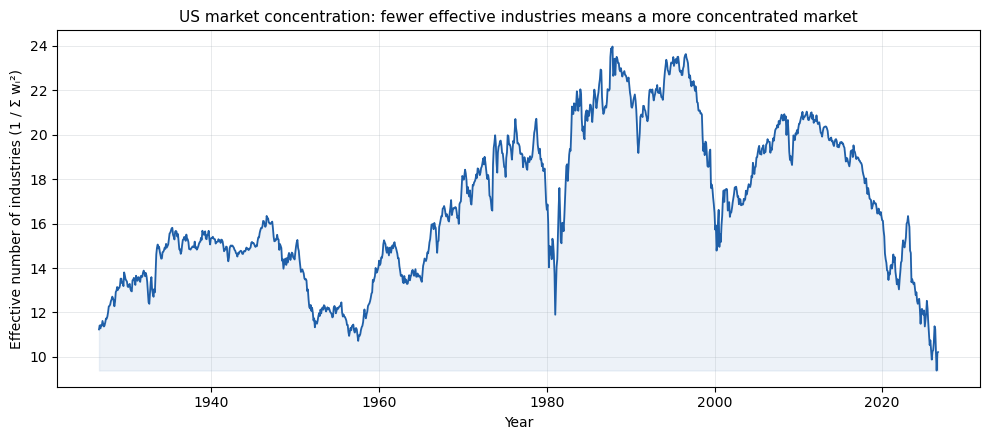

Effective industries: min 9.4, max 24.0, latest 10.2


In [4]:
from src import replication as rep, plots

weights = rep.industry_weights(industries["n_firms"], industries["avg_size"])
concentration = rep.effective_number(weights)
plots.plot_concentration_over_time(concentration)
plt.show()
print(f"Effective industries: min {concentration.min():.1f}, "
      f"max {concentration.max():.1f}, latest {concentration.dropna().iloc[-1]:.1f}")

In [5]:
predictive = rep.run_predictive_table(concentration, ff_factors)
predictive.to_csv(config.TABLES_DIR / "replication_predictive.csv")
predictive

,coef,t_stat,r_squared,n_obs
excess_return_1m,-0.0013,-0.8401,0.0006,"1,201.0000"
excess_return_3m,-0.0044,-1.0688,0.0020,"1,199.0000"
excess_return_12m,-0.0101,-0.6276,0.0024,"1,190.0000"
realised_vol_12m,-0.0125,-1.3997,0.0193,"1,190.0000"
max_drawdown_12m,0.0102,1.1151,0.0102,"1,190.0000"


In [6]:
timing = rep.concentration_timing_backtest(concentration, ff_factors)
timing.to_csv(config.TABLES_DIR / "replication_timing.csv")
timing

,ann_return,ann_vol,sharpe,max_drawdown
timing,0.0959,0.1793,0.4205,-0.8365
buy_and_hold,0.1038,0.1833,0.4545,-0.8365


## 3. The concentration dial and tail structure (H1)

Each year-end we rank the candidate pool by market cap and take the top 10 as that
year's cap-weighted "top sleeve". A dial portfolio blends the sleeve with the
equal-weight rest-of-market (RSP) at weights 20–50%, rebalanced monthly (40% ≈ today's
US market). We then test H1: does concentration leave returns alone but worsen the tail?

In [7]:
from src import portfolio as pf, concentration as cc, metrics as mx, plots

prices = candidate_prices.join(index_prices[[config.REST_OF_MARKET_TICKER]])
asset_returns = pf.daily_returns(prices)
month_caps = pf.month_end_market_caps(candidate_prices, shares)
sleeve_by_year = pf.annual_top_sleeve(month_caps, config.TOP_SLEEVE_SIZE)
sleeve_weights = pf.monthly_sleeve_weights(month_caps, sleeve_by_year)
built = pf.build_dial_returns(asset_returns, sleeve_weights)
dial_returns = {w: bt["returns"] for w, bt in built["dials"].items()}

In [8]:
sleeve_table = pd.DataFrame(
    {yr: pd.Series(names) for yr, names in sorted(sleeve_by_year.items()) if yr >= 2010}
).T
sleeve_table.columns = [f"rank_{i + 1}" for i in range(sleeve_table.shape[1])]
sleeve_table.index.name = "year"
sleeve_table.to_csv(config.TABLES_DIR / "dial_sleeve_composition.csv")
sleeve_table

,rank_1,rank_2,rank_3,rank_4,rank_5,rank_6,rank_7,rank_8,rank_9,rank_10
year,,,,,,,,,,
2010,GE,MSFT,JNJ,PG,JPM,BAC,ORCL,IBM,CSCO,WFC
2011,GE,MSFT,ORCL,PG,JPM,JNJ,WFC,BAC,IBM,CVX
2012,GE,MSFT,IBM,PG,JNJ,CVX,ORCL,WFC,INTC,PFE
2013,GE,MSFT,JNJ,ORCL,PG,IBM,WFC,CVX,JPM,KO
2014,GE,MSFT,JNJ,WFC,JPM,PG,ORCL,CVX,META,BAC
2015,GE,MSFT,JNJ,WFC,META,PG,JPM,ORCL,BAC,AAPL
2016,GE,MSFT,META,JNJ,WFC,JPM,PG,BAC,KO,AAPL
2017,GE,MSFT,META,JNJ,JPM,WFC,BAC,PG,CVX,AAPL
2018,GE,MSFT,META,JNJ,JPM,BAC,WFC,AAPL,PG,UNH


In [9]:
dial_metrics = pd.DataFrame(
    {f"{w:.0%}": mx.summary_metrics(r, config.TRADING_DAYS_PER_YEAR) for w, r in dial_returns.items()}
).T
dial_metrics.index.name = "dial"
dial_metrics.to_csv(config.TABLES_DIR / "dial_metrics.csv")
dial_metrics

,ann_return,ann_vol,sharpe,max_drawdown,worst_period,VaR95,ES95,VaR97.5,ES97.5
dial,,,,,,,,,
20%,0.1340,0.1776,0.7970,-0.3788,-0.1236,-0.0166,-0.0268,-0.0227,-0.0344
30%,0.1372,0.1787,0.8092,-0.3730,-0.1252,-0.0167,-0.0270,-0.0228,-0.0346
40%,0.1403,0.1805,0.8178,-0.3673,-0.1267,-0.0169,-0.0273,-0.0233,-0.0349
50%,0.1432,0.1832,0.8227,-0.3616,-0.1282,-0.0171,-0.0277,-0.0234,-0.0352


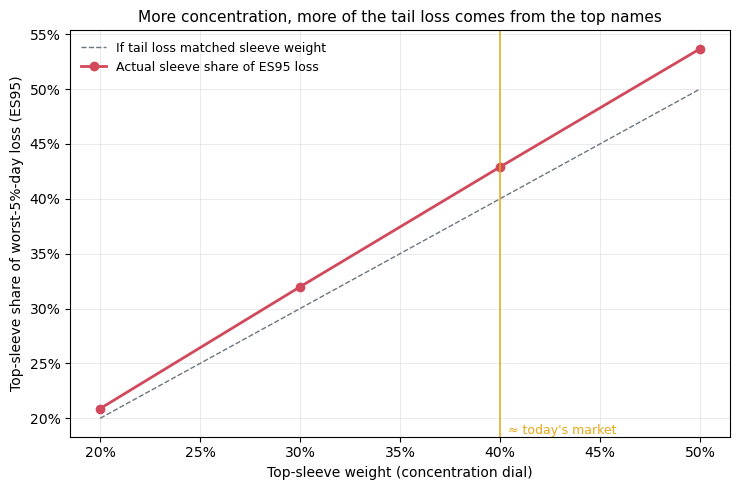

In [10]:
tail_share = pd.Series(
    {w: cc.top_sleeve_es_share(bt["returns"], cc.sleeve_contribution(bt["contributions"]), 0.95)
     for w, bt in built["dials"].items()}
)
plots.plot_tail_share_vs_concentration(tail_share)
plt.show()
tail_share.rename("es95_sleeve_share").to_frame().to_csv(config.TABLES_DIR / "dial_tail_share.csv")

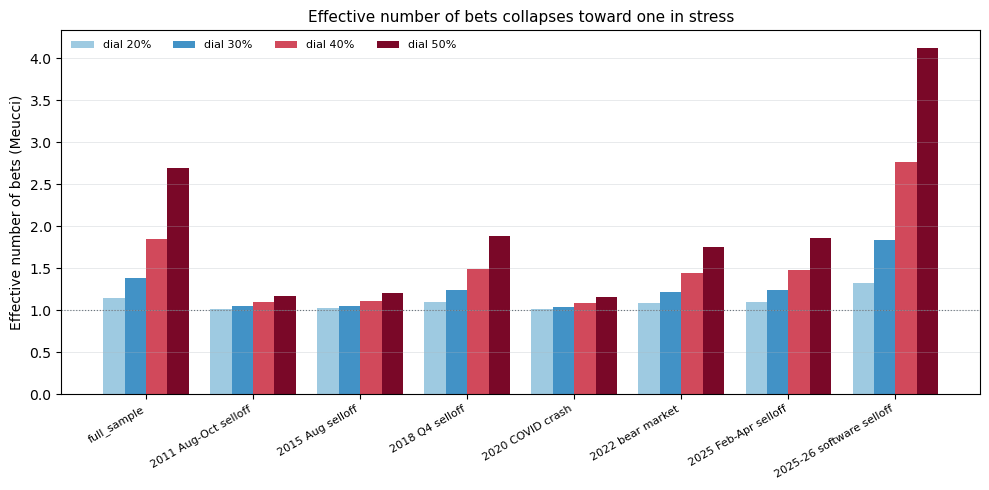

,0.2000,0.3000,0.4000,0.5000
full_sample,1.1500,1.3800,1.8400,2.7000
2011 Aug-Oct selloff,1.0200,1.0500,1.0900,1.1700
2015 Aug selloff,1.0200,1.0600,1.1100,1.2000
2018 Q4 selloff,1.0900,1.2400,1.4900,1.8900
2020 COVID crash,1.0200,1.0400,1.0900,1.1600
2022 bear market,1.0900,1.2200,1.4400,1.7500
2025 Feb-Apr selloff,1.0900,1.2400,1.4800,1.8600
2025-26 software selloff,1.3200,1.8300,2.7600,4.1300


In [11]:
enb_table = pd.DataFrame(
    {w: cc.enb_calm_vs_stress(bt["contributions"]) for w, bt in built["dials"].items()}
)
plots.plot_enb_calm_vs_stress(enb_table)
plt.show()
enb_table.to_csv(config.TABLES_DIR / "dial_enb.csv")
enb_table.round(2)

In [12]:
stress_returns = pd.DataFrame(
    {f"{w:.0%}": mx.stress_episode_returns(r, config.STRESS_EPISODES) for w, r in dial_returns.items()}
)
stress_returns.to_csv(config.TABLES_DIR / "dial_stress_returns.csv")
stress_returns

,20%,30%,40%,50%
2011 Aug-Oct selloff,-0.0372,-0.0373,-0.0375,-0.0377
2015 Aug selloff,-0.0555,-0.0560,-0.0564,-0.0569
2018 Q4 selloff,-0.1415,-0.1427,-0.1440,-0.1452
2020 COVID crash,-0.3765,-0.3708,-0.3650,-0.3592
2022 bear market,-0.1561,-0.1756,-0.1947,-0.2135
2025 Feb-Apr selloff,-0.1776,-0.1874,-0.1971,-0.2068
2025-26 software selloff,0.0668,0.0577,0.0485,0.0392


## 4. Managing concentration: rebalancing rules (H4, part 1)

Three ways to tame concentration without an overlay: cap any single name at 5%, weight
the sleeve equally, or hold a clustered inverse-volatility mix of the eleven assets. We
compare each with the unhedged dial on the same metrics, plus annual turnover.

In [13]:
from src import rebalancing as rb

def _rule_row(returns, weights):
    row = mx.summary_metrics(returns.loc[config.STOCK_ANALYSIS_START:], config.TRADING_DAYS_PER_YEAR)
    row["turnover"] = rb.annual_turnover(weights.loc[config.STOCK_ANALYSIS_START:], asset_returns)
    return row

rebal_rows = {}
for w_top in config.DIAL_LEVELS:
    dial_w = pf.dial_weight_matrix(sleeve_weights, w_top)
    rules = {
        "unhedged": dial_w,
        "5% cap": rb.cap_single_names(dial_w),
        "equal weight": rb.equal_weight_sleeve(sleeve_weights, w_top),
    }
    for rule, w in rules.items():
        returns = pf.run_backtest(asset_returns, w)["returns"]
        rebal_rows[(f"{w_top:.0%}", rule)] = _rule_row(returns, w)

civ_weights = rb.clustered_inverse_vol_weights(asset_returns, sleeve_by_year, sleeve_weights.index)
civ_returns = pf.run_backtest(asset_returns, civ_weights)["returns"]
rebal_rows[("11-asset", "clustered inverse-vol")] = _rule_row(civ_returns, civ_weights)

rebalancing_table = pd.DataFrame(rebal_rows).T
rebalancing_table.index.names = ["dial", "rule"]
rebalancing_table.to_csv(config.TABLES_DIR / "rebalancing_metrics.csv")
rebalancing_table

ann_return  ann_vol  sharpe  max_drawdown  \
dial     rule                                                               
20%      unhedged                   0.1340   0.1776  0.7970       -0.3788   
         5% cap                     0.1337   0.1775  0.7962       -0.3799   
         equal weight               0.1340   0.1770  0.7995       -0.3807   
30%      unhedged                   0.1372   0.1787  0.8092       -0.3730   
         5% cap                     0.1361   0.1779  0.8069       -0.3777   
         equal weight               0.1373   0.1773  0.8146       -0.3759   
40%      unhedged                   0.1403   0.1805  0.8178       -0.3673   
         5% cap                     0.1379   0.1782  0.8145       -0.3760   
         equal weight               0.1405   0.1782  0.8272       -0.3711   
50%      unhedged                   0.1432   0.1832  0.8227       -0.3616   
         5% cap                     0.1389   0.1783  0.8191       -0.3737   
         equal weight               0.1436   0.1796  0.8371       -0.3663   
11-asset clustered inverse-vol      0.1426   0.1837  0.8177       -0.3206   

                                worst_period   VaR95    ES95  VaR97.5  ES97.5  \
dial     rule                                                                   
20%      unhedged                    -0.1236 -0.0166 -0.0268  -0.0227 -0.0344   
         5% cap                      -0.1233 -0.0166 -0.0268  -0.0228 -0.0344   
         equal weight                -0.1228 -0.0163 -0.0266  -0.0225 -0.0342   
30%      unhedged                    -0.1252 -0.0167 -0.0270  -0.0228 -0.0346   
         5% cap                      -0.1240 -0.0167 -0.0269  -0.0229 -0.0344   
         equal weight                -0.1240 -0.0166 -0.0267  -0.0229 -0.0342   
40%      unhedged                    -0.1267 -0.0169 -0.0273  -0.0233 -0.0349   
         5% cap                      -0.1246 -0.0167 -0.0269  -0.0230 -0.0344   
         equal weight                -0.1252 -0.0167 -0.0268  -0.0227 -0.0343   
50%      unhedged                    -0.1282 -0.0171 -0.0277  -0.0234 -0.0352   
         5% cap                      -0.1248 -0.0168 -0.0269  -0.0229 -0.0343   
         equal weight                -0.1263 -0.0167 -0.0270  -0.0227 -0.0345   
11-asset clustered inverse-vol       -0.0813 -0.0176 -0.0274  -0.0236 -0.0348   

                                turnover  
dial     rule                             
20%      unhedged                 0.0931  
         5% cap                   0.0928  
         equal weight             0.1003  
30%      unhedged                 0.1310  
         5% cap                   0.1265  
         equal weight             0.1453  
40%      unhedged                 0.1632  
         5% cap                   0.1543  
         equal weight             0.1873  
50%      unhedged                 0.1898  
         5% cap                   0.1814  
         equal weight             0.2263  
11-asset clustered inverse-vol    1.4469